# Multi-SWE-bench

Exploratory analysis of the `multi_swebench` build of measurement-db, and the evidence behind the decisions in `scripts/preprocess/multi_swebench.py`. Outputs show counts and distributions only: issue text and patches are not printed (gated dataset).

## 1. Setup

In [1]:
import os
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")

import json
import re
import warnings
import sys
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from huggingface_hub import HfApi, hf_hub_download
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "scripts" / "preprocess"))
REPO = "aims-foundations/measurement-db"
B = "multi_swebench"
REVISION = HfApi().dataset_info(REPO).sha  # pinned for the whole notebook, as the preprocessing scripts do

warnings.filterwarnings("ignore", message=".*symlink.*")
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 160)
print("measurement-db revision:", REVISION)

measurement-db revision: 54074453da7b9911be0f48e4c560be547bc84d21


In [2]:
# Plot style (same palette as the other analysis notebooks): blue = success, orange = failure.
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, MUTED, SURFACE, GRID = "#0b0b0b", "#52514e", "#8a8984", "#fcfcfb", "#e6e5e1"
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#86b6ef", "#2a78d6", "#1c5cab", "#0d366b"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelsize": 9.5,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
    "legend.frameon": False, "legend.fontsize": 8.5, "font.size": 9.5,
})


def load(table, columns=None):
    """One formatted table at the pinned revision."""
    path = hf_hub_download(REPO, f"{B}/formatted_tables/{table}.parquet", repo_type="dataset", revision=REVISION)
    return pd.read_parquet(path, columns=columns)


def load_yaml(name):
    return yaml.safe_load(open(hf_hub_download(REPO, f"{B}/{name}", repo_type="dataset", revision=REVISION),
                               encoding="utf-8"))


def kv(s):
    """Parse 'k=v;k=v' into a dict."""
    return dict(p.split("=", 1) for p in s.split(";") if "=" in p) if isinstance(s, str) else {}


def null_report(df):
    return pd.DataFrame({"null_share": df.isna().mean().round(3), "distinct": df.nunique()})


def panels(n, width=5.2, height=3.4):
    fig, axes = plt.subplots(1, n, figsize=(width * n, height), squeeze=False)
    return fig, axes[0]


def show(fig):
    fig.tight_layout()
    plt.show()


def barh(ax, series, title, xlabel, color=BLUE, fmt="{:.2f}"):
    s = series[::-1]
    ax.barh([str(i) for i in s.index], s.values, color=color, height=0.65)
    for y, v in enumerate(s.values):
        ax.annotate(fmt.format(v), (v, y), xytext=(3, 0), textcoords="offset points", va="center",
                    fontsize=7.5, color=INK2)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", visible=False)

## 2. Metadata and provenance

In [3]:
bench = load("benchmarks").iloc[0]
meta, char = load_yaml("metadata.yaml"), load_yaml("characterization.yaml")
print(textwrap.fill(bench.description, 120), "\n")
print("testing_condition:\n" + textwrap.fill(meta["benchmark"]["testing_condition"], 120), "\n")
print("grading rule:", meta["grading"]["rule"], "\n")
display(bench[["name", "response_type", "multi_single_turn", "n_subjects", "n_items", "n_responses", "max_trial",
               "coverage", "release_date", "license"]].to_frame("value"))
for s in meta["sources"]["upstream"]:
    print(f"  {s['url']}  @ {s['revision'][:10]}")

Multi-SWE-bench tests whether coding agents can resolve real issues in open source repositories written in languages
beyond Python, such as Java, Go and Rust, counting an issue resolved only when the agent's patch passes the project's
tests. 

testing_condition:
settings: lang (the language the submission ran on, an item feature folded into item identity by the builder) and agent
(the scaffold, routed to the harness subject column so each scaffold+model submission stays a distinct subject). The
subject label is the model as upstream names it; response is 1 if the instance was resolved, 0 if unresolved, for
instances the submission attempted. test_condition is null. 

grading rule: The patch must pass the released FAIL_TO_PASS tests and preserve PASS_TO_PASS tests. 



,value
name,Multi-SWE-bench
response_type,binary
multi_single_turn,multi_turn
n_subjects,82
n_items,2127
n_responses,57975
max_trial,2
coverage,0.331596
release_date,2025-04
license,Apache-2.0


  https://github.com/multi-swe-bench/experiments  @ 6a7d5566f6
  https://huggingface.co/datasets/ByteDance-Seed/Multi-SWE-bench  @ 56ff018c04
  https://huggingface.co/datasets/princeton-nlp/SWE-bench_Verified  @ c104f840cc
  https://github.com/multi-swe-bench/MSWE-agent  @ 88217624b6
  https://github.com/multi-swe-bench/multi-swe-bench  @ 24f493f8a1


In [4]:
items, subjects, resp = load("items"), load("subjects"), load("responses")
traces = load("traces", columns=["response_id"])
display(pd.DataFrame({
    "declared_rows": {t: v["rows"] for t, v in char["tables"].items()},
    "actual_rows": {"items": len(items), "subjects": len(subjects), "responses": len(resp), "traces": len(traces),
                    "benchmarks": 1},
}))

,declared_rows,actual_rows
benchmarks,1,1
items,2127,2127
responses,57975,57975
subjects,82,82
traces,57184,57184


- Row counts match `characterization.yaml`. One response per instance a submission attempted, graded by the
  repository's tests (binary).

## 3. Subjects: model × scaffold submissions

In [5]:
print(f"{len(subjects)} subjects · distinct normalized_name: {subjects.normalized_name.nunique()} · "
      f"distinct harness: {subjects.harness.nunique()}")
display(null_report(subjects.drop(columns="subject_id")))
print("harness values:", subjects.harness.value_counts(dropna=False).to_dict())
print("access_date values:", subjects.access_date.value_counts().sort_index().to_dict())

82 subjects · distinct normalized_name: 20 · distinct harness: 11


,null_share,distinct
display_name,0.000,20
normalized_name,0.000,20
provider,0.000,10
release_date,0.024,18
access_date,0.000,11
harness,0.012,11
reasoning_effort,1.000,0
harness_version,1.000,0
subject_features_extra,1.000,0


harness values: {'MSWE-agent': 12, 'MagentLess': 12, 'MopenHands': 12, 'Agentless': 12, 'OpenHands': 12, 'SWE-agent': 12, 'RepoRepair': 3, 'InfCode': 2, 'CodeArts-Agent': 2, nan: 1, 'iSWE': 1, 'MSWE-Agent': 1}
access_date values: {'2025-03-29': 54, '2025-04-26': 18, '2025-09-10': 1, '2025-10-27': 1, '2025-11-10': 1, '2025-12-01': 1, '2025-12-26': 1, '2026-01-31': 1, '2026-02-02': 1, '2026-03-27': 2, '2026-06-24': 1}


In [6]:
n = resp.groupby("subject_id").size()
grid = (subjects.assign(responses=subjects.subject_id.map(n))
        .pivot_table(index="normalized_name", columns="harness", values="responses", aggfunc="sum"))
grid = grid.loc[grid.notna().sum(axis=1).sort_values(ascending=False).index]
display(grid.fillna(0).astype(int))

harness,Agentless,CodeArts-Agent,InfCode,MSWE-Agent,MSWE-agent,MagentLess,MopenHands,OpenHands,RepoRepair,SWE-agent,iSWE
normalized_name,,,,,,,,,,,
Anthropic Claude 3.5 Sonnet,495,0,0,0,1385,1234,1029,447,148,300,0
Alibaba Qwen2.5 72B,441,0,0,0,1019,966,1032,344,0,266,0
Anthropic Claude 3.7 Sonnet,481,0,0,0,1420,1188,1099,457,0,460,0
OpenAI o3-mini,471,0,0,0,1446,897,685,387,0,402,0
ByteDance Doubao 1.5 Pro,329,0,0,0,1145,636,808,219,0,210,0
DeepSeek R1,467,0,0,0,1442,1265,674,373,0,80,0
ByteDance Doubao 1.5 Thinking,490,0,0,0,1434,1211,1506,496,0,414,0
DeepSeek V3,489,0,0,0,1293,1260,792,457,0,115,0
Google Gemini 2.5 Pro,470,0,0,0,1457,1205,1503,500,0,330,0


- **82 subjects = 20 base models × 11 scaffolds.** The twelve models of the March/April 2025 release were each run
  with six scaffolds: the three Multi-SWE ports (MSWE-agent, MagentLess, MopenHands) on the seven non-Python
  languages, and the three originals (SWE-agent, Agentless, OpenHands) on Python (SWE-bench Verified). Later
  leaderboard entries add one scaffold each.
- Harness naming is inconsistent: `MSWE-Agent` vs `MSWE-agent`, and the iSWE-OpenModels submission has no
  harness (it is missing from the grid above for that reason). `reasoning_effort` is blank for every subject.

## 4. Items

In [7]:
items = items.assign(
    lang=items.item_features.str.extract(r"lang=([^;]+)", expand=False),
    repo=items.raw_item_id.str.rsplit("-", n=1).str[0],
    chars=items.content.str.len(),
)
print(f"{len(items):,} items · item_id unique: {items.item_id.is_unique} · raw_item_id unique: "
      f"{items.raw_item_id.is_unique} · repos: {items.repo.nunique()}")
print("verifier class:", items.verifier.map(lambda v: json.loads(v)["class"]).value_counts().to_dict())
by_lang = items.groupby("lang").agg(items=("item_id", "size"), repos=("repo", "nunique"),
                                    median_chars=("chars", "median"))
display(by_lang.sort_values("items", ascending=False))
print("content_hash duplicates:", items.content_hash.duplicated().sum())

2,127 items · item_id unique: True · raw_item_id unique: True · repos: 51


verifier class: {'exact_matcher': 2127}


,items,repos,median_chars
lang,,,
python,500,12,1195.5
go,428,3,858.0
javascript,356,6,1113.5
rust,239,10,1575.0
typescript,224,3,1446.5
c++,129,5,1028.0
c,128,3,964.0
java,123,9,1547.0


content_hash duplicates: 49


- 2,127 items in 8 languages from 51 repositories; `raw_item_id` is unique. The 500 Python items are SWE-bench
  Verified. Go, JavaScript and TypeScript come from only 3–6 repositories each, so repository and language are
  hard to separate.

## 5. Responses in the build

57,975 responses · missing scores: 0 · values: [np.float64(0.0), np.float64(1.0)] · trials: {1: 57835, 2: 140}
trial 2 rows: 140 on 5 items of 1 repo(s): ['elastic__logstash']
build resolve rate: 0.148


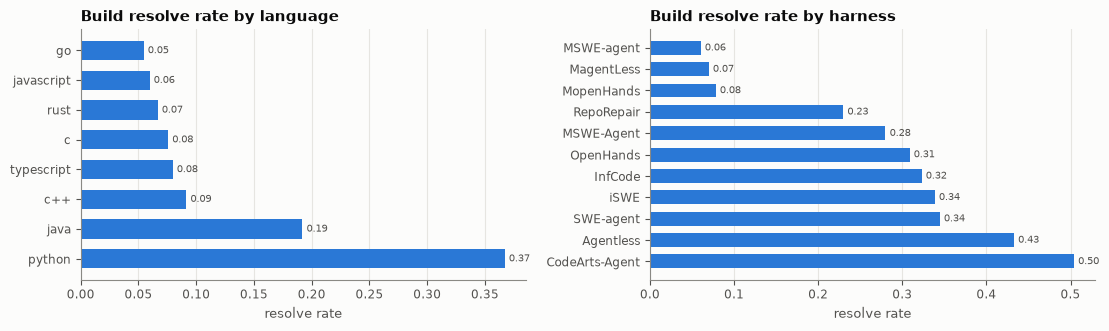

In [8]:
print(f"{len(resp):,} responses · missing scores: {resp.response.isna().sum()} · values: "
      f"{sorted(resp.response.unique())} · trials: {resp.trial.value_counts().to_dict()}")
r = resp.merge(items[["item_id", "lang", "repo"]], on="item_id").merge(
    subjects[["subject_id", "normalized_name", "harness"]], on="subject_id")
twice = r[r.trial == 2]
print(f"trial 2 rows: {len(twice)} on {twice.item_id.nunique()} items of {twice.repo.nunique()} repo(s): "
      f"{sorted(twice.repo.unique())}")
print(f"build resolve rate: {r.response.mean():.3f}")
fig, axes = panels(2, width=5.6)
barh(axes[0], r.groupby("lang").response.mean().sort_values(), "Build resolve rate by language", "resolve rate")
barh(axes[1], r.groupby("harness").response.mean().sort_values(), "Build resolve rate by harness", "resolve rate")
show(fig)

- Build resolve rate 0.148. The only repeated attempts (trial 2) are 140 rows on five `elastic/logstash`
  items.

## 6. What the build leaves out

Each run's `results.json` sorts the submitted instances into resolved, unresolved, no test report (`empty_error_patch_ids`, or `error_ids` / `empty_patch_ids` in newer files) and incomplete. The build keeps only resolved and unresolved. The run's prediction file tells whether a no-report instance had an empty patch.

In [9]:
import multi_swebench as mswe
results_files, preds_files = mswe.source_files(REVISION)
files = {f: Path(hf_hub_download(REPO, f, repo_type="dataset", revision=REVISION))
         for f in results_files + preds_files}
out = mswe.outcomes(results_files, files, subjects).merge(items[["item_id", "raw_item_id"]], on="raw_item_id",
                                                           how="left")
out["kind"] = np.select(
    [out.group.isin(["resolved", "unresolved", "incomplete"]), out.patch_empty.eq(True), out.patch_empty.eq(False)],
    [out.group, "no report · empty patch", "no report · non-empty patch"], "no report · patch unavailable")
summary = out.groupby("kind").agg(instances=("raw_item_id", "size"), without_task=("item_id", lambda s: s.isna().sum()))
summary["share"] = (summary.instances / summary.instances.sum()).round(3)
display(summary.sort_values("instances", ascending=False))
unavailable = out[out.patch_empty.isna() & out.group.eq("no_report")]
print(f"{len(results_files)} runs · runs with no-report instances whose patch is unavailable: "
      f"{unavailable.run.nunique()} ({len(unavailable)} instances)")

,instances,without_task,share
kind,,,
unresolved,49398,154,0.630
no report · empty patch,11692,20,0.149
no report · non-empty patch,8667,30,0.111
resolved,8577,1,0.109
no report · patch unavailable,96,0,0.001
incomplete,4,0,0.000


299 runs · runs with no-report instances whose patch is unavailable: 15 (96 instances)


In [10]:
# Where empty patches come from: share of each scaffold's submitted instances.
h = out.merge(subjects[["subject_id", "harness"]], on="subject_id")
share = pd.crosstab(h.harness, h.kind, normalize="index")
cols = ["resolved", "unresolved", "no report · empty patch", "no report · non-empty patch"]
display(share[[c for c in cols if c in share]].round(3).sort_values("no report · empty patch", ascending=False))

kind,resolved,unresolved,no report · empty patch,no report · non-empty patch
harness,,,,
SWE-agent,0.195,0.372,0.427,0.006
MagentLess,0.050,0.665,0.250,0.035
MSWE-agent,0.048,0.754,0.098,0.099
MopenHands,0.051,0.596,0.077,0.275
OpenHands,0.257,0.575,0.066,0.101
Agentless,0.405,0.530,0.064,0.000
CodeArts-Agent,0.496,0.488,0.008,0.000
InfCode,0.323,0.677,0.000,0.000
MSWE-Agent,0.280,0.720,0.000,0.000


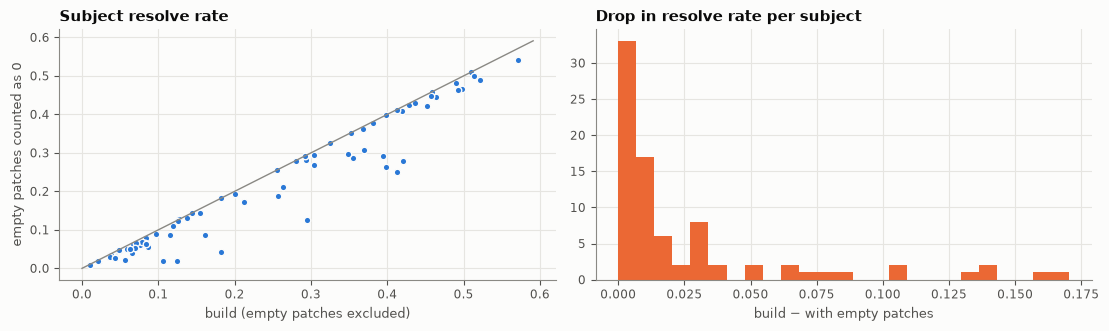

overall: build 0.148 → with empty patches 0.123
rank correlation of subject rates (Spearman): 0.95


,largest drop
subject_id,
Doubao-1.5-pro · Agentless,0.136176
DeepSeek-V3 · SWE-agent,0.140525
Gemini-2.5-Pro · SWE-agent,0.142655
Claude-3.5-Sonnet(Oct) · SWE-agent,0.161812
Doubao-1.5-pro · SWE-agent,0.170490


In [11]:
# Effect on resolve rates: build (resolved / graded) vs counting empty patches as failures.
per = out[out.item_id.notna()].groupby("subject_id").kind.value_counts().unstack(fill_value=0)
per["build"] = per.resolved / (per.resolved + per.unresolved)
per["with_empty"] = per.resolved / (per.resolved + per.unresolved + per["no report · empty patch"])
lab = subjects.set_index("subject_id").apply(lambda s: f"{s.display_name} · {s.harness}", axis=1)
fig, axes = panels(2, width=5.6)
axes[0].scatter(per.build, per.with_empty, s=22, color=BLUE, edgecolor=SURFACE)
lim = [0, per.build.max() + 0.02]
axes[0].plot(lim, lim, color=MUTED, linewidth=1)
axes[0].set_title("Subject resolve rate")
axes[0].set_xlabel("build (empty patches excluded)")
axes[0].set_ylabel("empty patches counted as 0")
change = (per.build - per.with_empty).sort_values()
axes[1].hist(change, bins=25, color=ORANGE)
axes[1].set_title("Drop in resolve rate per subject")
axes[1].set_xlabel("build − with empty patches")
show(fig)
print(f"overall: build {per.resolved.sum() / (per.resolved + per.unresolved).sum():.3f} → with empty patches "
      f"{per.resolved.sum() / (per.resolved + per.unresolved + per['no report · empty patch']).sum():.3f}")
print("rank correlation of subject rates (Spearman):", round(per.build.rank().corr(per.with_empty.rank()), 3))
display(change.tail(5).rename(index=lab).rename("largest drop").to_frame())

- **The build drops a quarter of the submitted instances.** Besides 4 incomplete evaluations, 20,455 instances
  have no test report: 11,692 with an empty patch, 8,667 with a non-empty patch, and 96 whose patch is not
  available.
- **Empty patches are model failures**: the agent stopped without changing the code. They are concentrated in
  some scaffolds (43% of SWE-agent's Python instances, 25% of MagentLess's). Leaving them out credits a
  scaffold for the instances it gave up on, and makes an item look easier for the subjects that crashed on it.
- **Counting them as 0** lowers the overall resolve rate from 0.148 to 0.123. Subject rankings barely change
  (Spearman 0.95), but individual subjects lose up to 0.17.
- **A non-empty patch without a report is ambiguous.** It may not apply (model failure) or the test environment
  may have failed (infrastructure); `results.json` does not say which, so these instances stay out.

## 7. Decisions for the final dataset

Implemented in `scripts/preprocess/multi_swebench.py` (see its docstring).

In [12]:
path = ROOT / "data" / "processed" / f"{B}.jsonl"
if path.exists():
    cols = ["subject_id", "item_id", "score", "n_runs", "harness", "programming_language", "model_family", "thinking"]
    final = pd.concat(chunk[cols] for chunk in pd.read_json(path, lines=True, chunksize=10_000))  # ~0.8 GB file
    print(f"{len(final):,} rows · {final.subject_id.nunique()} subjects · {final.item_id.nunique():,} items · "
          f"mean score {final.score.mean():.3f}")
    print("harness:", final.drop_duplicates("subject_id").harness.value_counts(dropna=False).to_dict())
else:
    print("run scripts/preprocess/multi_swebench.py first")

69,500 rows · 82 subjects · 2,127 items · mean score 0.123
harness: {'MSWE-agent': 13, 'SWE-agent': 12, 'OpenHands': 12, 'MopenHands': 12, 'MagentLess': 12, 'Agentless': 12, 'RepoRepair': 3, 'iSWE': 2, 'InfCode': 2, 'CodeArts-Agent': 2}


- **D1**: empty-patch instances enter as 0 (11,665 after skipping instances without a task definition or with a
  build response already).
- **D2**: instances with a non-empty patch but no report, with an unavailable patch, or incomplete are dropped.
- **D3**: harness names harmonised (`MSWE-Agent` → `MSWE-agent`; iSWE-OpenModels → `iSWE`).
- **D4 items**: `item_id = multi_swebench:<raw_item_id>`; `programming_language` from `lang`; `eval_type` =
  unit_tests; `ground_truth` = the gold patch. score = mean over attempts.